In [1]:
import nltk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from nltk.corpus import wordnet as wn
from nltk.tokenize import word_tokenize
from nltk.wsd import lesk
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import warnings
warnings.filterwarnings('ignore')

nltk.download('wordnet', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('omw-1.4', quiet=True)

/Users/shreyjain/Documents/CODING/MCA-Assignments/Trimester-5/nlp/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

In [2]:
queries_data = [
    {
        'query': 'I want to book a table at the restaurant',
        'ambiguous_word': 'book',
        'context': 'reservation'
    },
    {
        'query': 'I read a book about history',
        'ambiguous_word': 'book',
        'context': 'literature'
    },
    {
        'query': 'The bat is hanging upside down',
        'ambiguous_word': 'bat',
        'context': 'animal'
    },
    {
        'query': 'He swung the bat to hit the ball',
        'ambiguous_word': 'bat',
        'context': 'sports equipment'
    },
    {
        'query': 'I saw the bank of the river',
        'ambiguous_word': 'bank',
        'context': 'riverbank'
    },
    {
        'query': 'I went to the bank to withdraw money',
        'ambiguous_word': 'bank',
        'context': 'financial institution'
    },
    {
        'query': 'The light in the room was too bright',
        'ambiguous_word': 'light',
        'context': 'illumination'
    },
    {
        'query': 'This bag is very light to carry',
        'ambiguous_word': 'light',
        'context': 'weight'
    },
    {
        'query': 'Cricket match was very exciting today',
        'ambiguous_word': 'match',
        'context': 'sports game'
    },
    {
        'query': 'I used a match to light the candle',
        'ambiguous_word': 'match',
        'context': 'fire starter'
    },
    {
        'query': 'The company will run the operation efficiently',
        'ambiguous_word': 'run',
        'context': 'management'
    },
    {
        'query': 'I run every morning for exercise',
        'ambiguous_word': 'run',
        'context': 'movement'
    },
    {
        'query': 'Can you check the file on your computer',
        'ambiguous_word': 'file',
        'context': 'document'
    },
    {
        'query': 'I used a file to smooth the wood',
        'ambiguous_word': 'file',
        'context': 'tool'
    },
    {
        'query': 'The current is strong in this river',
        'ambiguous_word': 'current',
        'context': 'water flow'
    },
    {
        'query': 'The current weather is cold today',
        'ambiguous_word': 'current',
        'context': 'present time'
    }
]

dataset = pd.DataFrame(queries_data)
dataset

,query,ambiguous_word,context
0,I want to book a table at the restaurant,book,reservation
1,I read a book about history,book,literature
2,The bat is hanging upside down,bat,animal
3,He swung the bat to hit the ball,bat,sports equipment
4,I saw the bank of the river,bank,riverbank
5,I went to the bank to withdraw money,bank,financial institution
6,The light in the room was too bright,light,illumination
7,This bag is very light to carry,light,weight
8,Cricket match was very exciting today,match,sports game
9,I used a match to light the candle,match,fire starter


In [3]:
def get_sense_dictionary(word):
    synsets = wn.synsets(word)
    
    if not synsets:
        return {
            'word': word,
            'found': False,
            'senses': []
        }
    
    senses = []
    for synset in synsets:
        sense_info = {
            'synset_id': str(synset),
            'pos': synset.pos(),
            'definition': synset.definition(),
            'examples': synset.examples()
        }
        senses.append(sense_info)
    
    return {
        'word': word,
        'found': True,
        'senses': senses
    }

sense_dictionaries = {}
for word in dataset['ambiguous_word'].unique():
    sense_dictionaries[word] = get_sense_dictionary(word)

for word, sense_dict in sense_dictionaries.items():
    print(f"\n{'='*80}")
    print(f"Word: {word}")
    print(f"{'='*80}")
    if sense_dict['found']:
        print(f"Found {len(sense_dict['senses'])} senses\n")
        for i, sense in enumerate(sense_dict['senses'], 1):
            print(f"{i}. Synset: {sense['synset_id']}")
            print(f"   POS: {sense['pos']}")
            print(f"   Definition: {sense['definition']}")
            print(f"   Examples: {sense['examples']}\n")
    else:
        print(f"No senses found for '{word}' in WordNet")


Word: book
Found 15 senses

1. Synset: Synset('book.n.01')
   POS: n
   Definition: a written work or composition that has been published (printed on pages bound together)
   Examples: ['I am reading a good book on economics']

2. Synset: Synset('book.n.02')
   POS: n
   Definition: physical objects consisting of a number of pages bound together
   Examples: ['he used a large book as a doorstop']

3. Synset: Synset('record.n.05')
   POS: n
   Definition: a compilation of the known facts regarding something or someone
   Examples: ["Al Smith used to say, `Let's look at the record'", 'his name is in all the record books']

4. Synset: Synset('script.n.01')
   POS: n
   Definition: a written version of a play or other dramatic composition; used in preparing for a performance
   Examples: []

5. Synset: Synset('ledger.n.01')
   POS: n
   Definition: a record in which commercial accounts are recorded
   Examples: ['they got a subpoena to examine our books']

6. Synset: Synset('book.n.06')
 

In [4]:
def apply_lesk_wsd(query, target_word):
    tokens = word_tokenize(query.lower())
    synset = lesk(tokens, target_word)
    
    if synset is None:
        return {
            'method': 'Lesk',
            'found': False,
            'synset_id': None,
            'definition': 'No sense found',
            'pos': None
        }
    
    return {
        'method': 'Lesk',
        'found': True,
        'synset_id': str(synset),
        'definition': synset.definition(),
        'pos': synset.pos()
    }

lesk_results = []
for idx, row in dataset.iterrows():
    result = apply_lesk_wsd(row['query'], row['ambiguous_word'])
    result['query'] = row['query']
    result['ambiguous_word'] = row['ambiguous_word']
    lesk_results.append(result)

lesk_df = pd.DataFrame(lesk_results)
lesk_df

,method,found,synset_id,definition,pos,query,ambiguous_word
0,Lesk,True,Synset('koran.n.01'),the sacred writings of Islam revealed by God t...,n,I want to book a table at the restaurant,book
1,Lesk,True,Synset('script.n.01'),a written version of a play or other dramatic ...,n,I read a book about history,book
2,Lesk,True,Synset('cricket_bat.n.01'),the club used in playing cricket,n,The bat is hanging upside down,bat
3,Lesk,True,Synset('bat.n.02'),(baseball) a turn trying to get a hit,n,He swung the bat to hit the ball,bat
4,Lesk,True,Synset('bank.v.07'),cover with ashes so to control the rate of bur...,v,I saw the bank of the river,bank
5,Lesk,True,Synset('savings_bank.n.02'),a container (usually with a slot in the top) f...,n,I went to the bank to withdraw money,bank
6,Lesk,True,Synset('luminosity.n.01'),the quality of being luminous; emitting or ref...,n,The light in the room was too bright,light
7,Lesk,True,Synset('light.s.22'),designed for ease of movement or to carry litt...,s,This bag is very light to carry,light
8,Lesk,True,Synset('match.n.05'),the score needed to win a match,n,Cricket match was very exciting today,match
9,Lesk,True,Synset('match.n.05'),the score needed to win a match,n,I used a match to light the candle,match


In [5]:
model = SentenceTransformer('all-MiniLM-L6-v2')

def apply_embedding_wsd(query, target_word):
    synsets = wn.synsets(target_word)
    
    if not synsets:
        return {
            'method': 'Embedding',
            'found': False,
            'synset_id': None,
            'definition': 'No sense found',
            'pos': None,
            'similarity_score': 0.0
        }
    
    query_embedding = model.encode(query, convert_to_tensor=True)
    
    best_synset = None
    best_score = -1
    
    for synset in synsets:
        definition = synset.definition()
        def_embedding = model.encode(definition, convert_to_tensor=True)
        
        similarity = cosine_similarity(
            query_embedding.cpu().detach().numpy().reshape(1, -1),
            def_embedding.cpu().detach().numpy().reshape(1, -1)
        )[0][0]
        
        if similarity > best_score:
            best_score = similarity
            best_synset = synset
    
    return {
        'method': 'Embedding',
        'found': True,
        'synset_id': str(best_synset),
        'definition': best_synset.definition(),
        'pos': best_synset.pos(),
        'similarity_score': float(best_score)
    }

embedding_results = []
for idx, row in dataset.iterrows():
    result = apply_embedding_wsd(row['query'], row['ambiguous_word'])
    result['query'] = row['query']
    result['ambiguous_word'] = row['ambiguous_word']
    embedding_results.append(result)

embedding_df = pd.DataFrame(embedding_results)
embedding_df

,method,found,synset_id,definition,pos,similarity_score,query,ambiguous_word
0,Embedding,True,Synset('book.v.04'),register in a hotel booker,v,0.297680,I want to book a table at the restaurant,book
1,Embedding,True,Synset('record.n.05'),a compilation of the known facts regarding som...,n,0.326027,I read a book about history,book
2,Embedding,True,Synset('bat.v.03'),have a turn at bat,v,0.617297,The bat is hanging upside down,bat
3,Embedding,True,Synset('bat.v.01'),"strike with, or as if with a baseball bat",v,0.616030,He swung the bat to hit the ball,bat
4,Embedding,True,Synset('bank.v.02'),enclose with a bank,v,0.402348,I saw the bank of the river,bank
5,Embedding,True,Synset('deposit.v.02'),put into a bank account,v,0.564446,I went to the bank to withdraw money,bank
6,Embedding,True,Synset('light.v.01'),make lighter or brighter,v,0.417287,The light in the room was too bright,light
7,Embedding,True,Synset('light.s.22'),designed for ease of movement or to carry litt...,s,0.369846,This bag is very light to carry,light
8,Embedding,True,Synset('match.n.05'),the score needed to win a match,n,0.431990,Cricket match was very exciting today,match
9,Embedding,True,Synset('match.n.01'),lighter consisting of a thin piece of wood or ...,n,0.334087,I used a match to light the candle,match


In [6]:
comparison_results = []

for idx, row in dataset.iterrows():
    lesk_row = lesk_df.iloc[idx]
    embed_row = embedding_df.iloc[idx]
    
    agreement = (lesk_row['synset_id'] == embed_row['synset_id']) if (lesk_row['found'] and embed_row['found']) else False
    
    comparison_results.append({
        'query': row['query'],
        'ambiguous_word': row['ambiguous_word'],
        'context': row['context'],
        'lesk_synset': lesk_row['synset_id'],
        'lesk_definition': lesk_row['definition'],
        'embedding_synset': embed_row['synset_id'],
        'embedding_definition': embed_row['definition'],
        'embedding_score': embed_row['similarity_score'],
        'agreement': agreement
    })

comparison_df = pd.DataFrame(comparison_results)

agreement_count = comparison_df['agreement'].sum()
total_queries = len(comparison_df)

comparison_summary = {
    'Total Queries': total_queries,
    'Agreed': agreement_count,
    'Disagreed': total_queries - agreement_count,
    'Agreement Rate': f"{(agreement_count/total_queries)*100:.2f}%"
}

comparison_summary_df = pd.DataFrame([comparison_summary])
comparison_summary_df

,Total Queries,Agreed,Disagreed,Agreement Rate
0,16,5,11,31.25%


In [7]:
def compute_all_sense_similarities(query, target_word):
    synsets = wn.synsets(target_word)
    
    if not synsets:
        return None
    
    query_embedding = model.encode(query, convert_to_tensor=True)
    similarities = {}
    
    for synset in synsets:
        definition = synset.definition()
        def_embedding = model.encode(definition, convert_to_tensor=True)
        
        similarity = cosine_similarity(
            query_embedding.cpu().detach().numpy().reshape(1, -1),
            def_embedding.cpu().detach().numpy().reshape(1, -1)
        )[0][0]
        
        similarities[str(synset)] = {
            'synset_id': str(synset),
            'definition': definition,
            'similarity_score': float(similarity)
        }
    
    return similarities

all_similarities = {}
for idx, row in dataset.iterrows():
    word = row['ambiguous_word']
    query = row['query']
    
    if word not in all_similarities:
        all_similarities[word] = {}
    
    sims = compute_all_sense_similarities(query, word)
    if sims:
        all_similarities[word][query] = sims

word = 'book'
book_query_1 = dataset[dataset['query'] == 'I want to book a table at the restaurant']['query'].values[0]
book_similarities = all_similarities['book'][book_query_1]

book_sim_df = pd.DataFrame([
    {
        'Sense': sim_data['synset_id'],
        'Definition': sim_data['definition'],
        'Similarity Score': sim_data['similarity_score']
    }
    for sim_data in book_similarities.values()
]).sort_values('Similarity Score', ascending=False)

book_sim_df

,Sense,Definition,Similarity Score
14,Synset('book.v.04'),register in a hotel booker,0.297680
10,Synset('book.n.11'),a number of sheets (ticket or stamps etc.) bou...,0.270754
12,Synset('reserve.v.04'),arrange for and reserve (something for someone...,0.247438
1,Synset('book.n.02'),physical objects consisting of a number of pag...,0.230255
0,Synset('book.n.01'),a written work or composition that has been pu...,0.211324
4,Synset('ledger.n.01'),a record in which commercial accounts are reco...,0.192675
5,Synset('book.n.06'),a collection of playing cards satisfying the r...,0.160481
13,Synset('book.v.03'),record a charge in a police register,0.156186
11,Synset('book.v.01'),engage for a performance,0.145459
3,Synset('script.n.01'),a written version of a play or other dramatic ...,0.130456


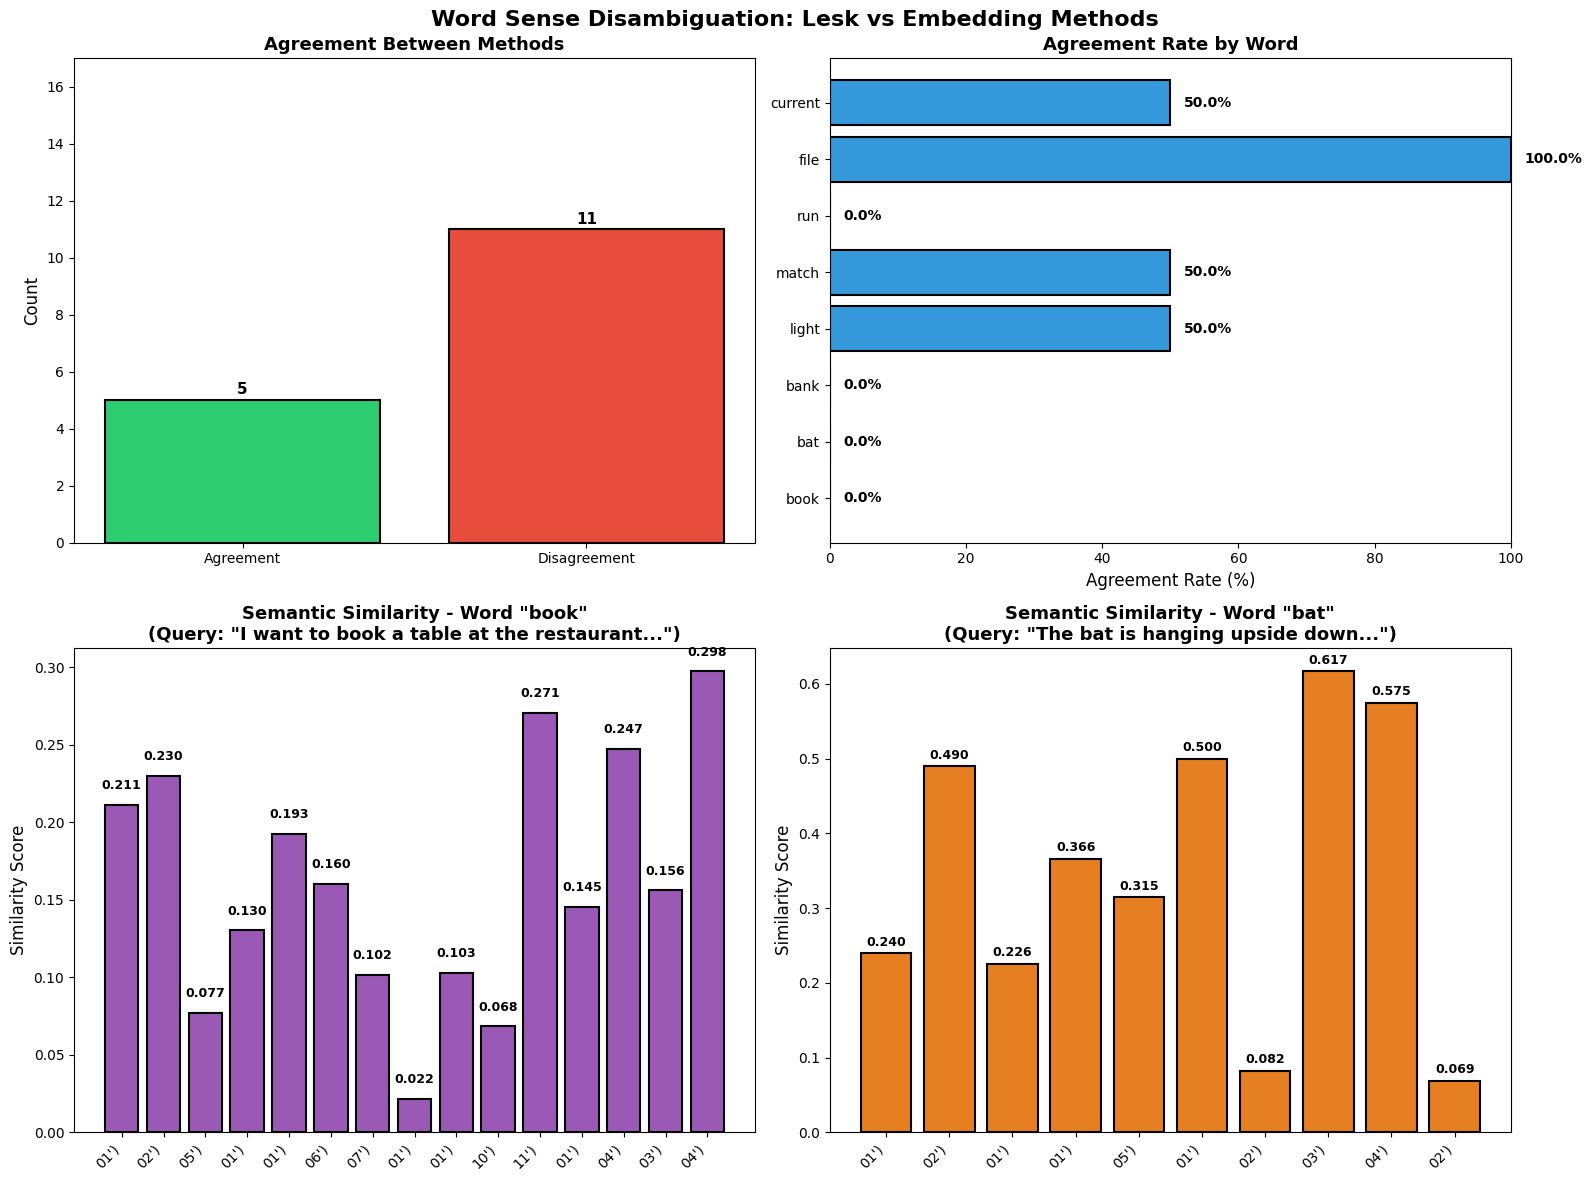

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Word Sense Disambiguation: Lesk vs Embedding Methods', fontsize=16, fontweight='bold')

ax1 = axes[0, 0]
agreement_data = [agreement_count, total_queries - agreement_count]
colors = ['#2ecc71', '#e74c3c']
ax1.bar(['Agreement', 'Disagreement'], agreement_data, color=colors, edgecolor='black', linewidth=1.5)
ax1.set_ylabel('Count', fontsize=12)
ax1.set_title('Agreement Between Methods', fontsize=13, fontweight='bold')
ax1.set_ylim(0, total_queries + 1)
for i, v in enumerate(agreement_data):
    ax1.text(i, v + 0.2, str(v), ha='center', fontweight='bold', fontsize=11)

ax2 = axes[0, 1]
word_agreement = {}
for word in dataset['ambiguous_word'].unique():
    word_data = comparison_df[comparison_df['ambiguous_word'] == word]
    word_agreement[word] = word_data['agreement'].sum() / len(word_data) * 100

words = list(word_agreement.keys())
rates = list(word_agreement.values())
ax2.barh(words, rates, color='#3498db', edgecolor='black', linewidth=1.5)
ax2.set_xlabel('Agreement Rate (%)', fontsize=12)
ax2.set_title('Agreement Rate by Word', fontsize=13, fontweight='bold')
ax2.set_xlim(0, 100)
for i, v in enumerate(rates):
    ax2.text(v + 2, i, f'{v:.1f}%', va='center', fontweight='bold', fontsize=10)

ax3 = axes[1, 0]
book_query = dataset[dataset['ambiguous_word'] == 'book']['query'].values[0]
book_sims = all_similarities['book'][book_query]
synset_labels = [sim['synset_id'].split('.')[-1] for sim in book_sims.values()]
scores = [sim['similarity_score'] for sim in book_sims.values()]
bars = ax3.bar(range(len(synset_labels)), scores, color='#9b59b6', edgecolor='black', linewidth=1.5)
ax3.set_xticks(range(len(synset_labels)))
ax3.set_xticklabels(synset_labels, rotation=45, ha='right')
ax3.set_ylabel('Similarity Score', fontsize=12)
ax3.set_title(f'Semantic Similarity - Word "book"\n(Query: "{book_query[:40]}...")', fontsize=13, fontweight='bold')
for i, (bar, score) in enumerate(zip(bars, scores)):
    ax3.text(i, score + 0.01, f'{score:.3f}', ha='center', fontweight='bold', fontsize=9)

ax4 = axes[1, 1]
bat_query = dataset[dataset['ambiguous_word'] == 'bat']['query'].values[0]
bat_sims = all_similarities['bat'][bat_query]
synset_labels_bat = [sim['synset_id'].split('.')[-1] for sim in bat_sims.values()]
scores_bat = [sim['similarity_score'] for sim in bat_sims.values()]
bars_bat = ax4.bar(range(len(synset_labels_bat)), scores_bat, color='#e67e22', edgecolor='black', linewidth=1.5)
ax4.set_xticks(range(len(synset_labels_bat)))
ax4.set_xticklabels(synset_labels_bat, rotation=45, ha='right')
ax4.set_ylabel('Similarity Score', fontsize=12)
ax4.set_title(f'Semantic Similarity - Word "bat"\n(Query: "{bat_query[:40]}...")', fontsize=13, fontweight='bold')
for i, (bar, score) in enumerate(zip(bars_bat, scores_bat)):
    ax4.text(i, score + 0.01, f'{score:.3f}', ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

In [9]:
detailed_comparison = []
for idx, row in comparison_df.iterrows():
    detailed_comparison.append({
        'Query': row['query'][:50] + '...' if len(row['query']) > 50 else row['query'],
        'Word': row['ambiguous_word'],
        'Context': row['context'],
        'Lesk Method': row['lesk_synset'] if row['lesk_synset'] else 'Not Found',
        'Embedding Method': row['embedding_synset'] if row['embedding_synset'] else 'Not Found',
        'Embedding Score': f"{row['embedding_score']:.3f}",
        'Agreement': 'Yes' if row['agreement'] else 'No'
    })

detailed_df = pd.DataFrame(detailed_comparison)
detailed_df

,Query,Word,Context,Lesk Method,Embedding Method,Embedding Score,Agreement
0,I want to book a table at the restaurant,book,reservation,Synset('koran.n.01'),Synset('book.v.04'),0.298,No
1,I read a book about history,book,literature,Synset('script.n.01'),Synset('record.n.05'),0.326,No
2,The bat is hanging upside down,bat,animal,Synset('cricket_bat.n.01'),Synset('bat.v.03'),0.617,No
3,He swung the bat to hit the ball,bat,sports equipment,Synset('bat.n.02'),Synset('bat.v.01'),0.616,No
4,I saw the bank of the river,bank,riverbank,Synset('bank.v.07'),Synset('bank.v.02'),0.402,No
5,I went to the bank to withdraw money,bank,financial institution,Synset('savings_bank.n.02'),Synset('deposit.v.02'),0.564,No
6,The light in the room was too bright,light,illumination,Synset('luminosity.n.01'),Synset('light.v.01'),0.417,No
7,This bag is very light to carry,light,weight,Synset('light.s.22'),Synset('light.s.22'),0.370,Yes
8,Cricket match was very exciting today,match,sports game,Synset('match.n.05'),Synset('match.n.05'),0.432,Yes
9,I used a match to light the candle,match,fire starter,Synset('match.n.05'),Synset('match.n.01'),0.334,No


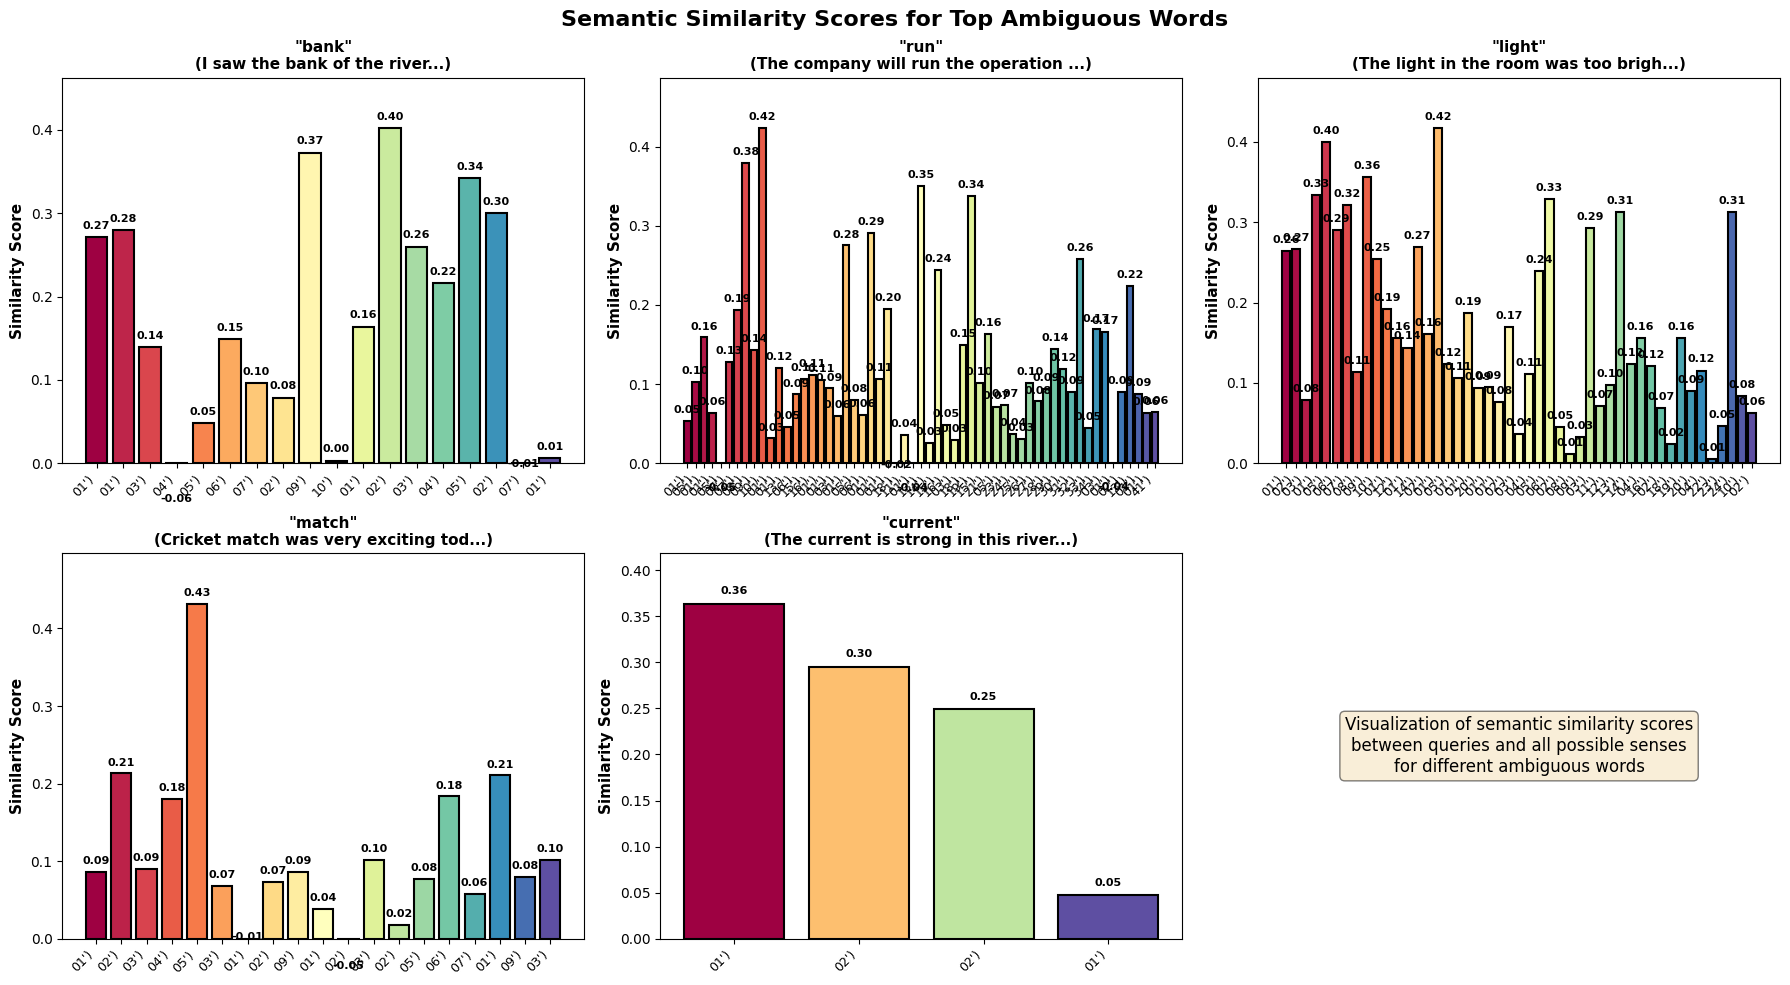

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Semantic Similarity Scores for Top Ambiguous Words', fontsize=16, fontweight='bold')

selected_words = ['bank', 'run', 'light', 'match', 'current']
selected_queries = {}

for word in selected_words:
    word_queries = dataset[dataset['ambiguous_word'] == word]['query'].values
    if len(word_queries) > 0:
        selected_queries[word] = word_queries[0]

flat_axes = axes.flatten()

for idx, word in enumerate(selected_words):
    if word in selected_queries:
        query = selected_queries[word]
        sims = all_similarities[word][query]
        
        synset_labels = [sim['synset_id'].split('.')[-1] for sim in sims.values()]
        scores = [sim['similarity_score'] for sim in sims.values()]
        
        ax = flat_axes[idx]
        colors = plt.cm.Spectral(np.linspace(0, 1, len(synset_labels)))
        bars = ax.bar(range(len(synset_labels)), scores, color=colors, edgecolor='black', linewidth=1.5)
        
        ax.set_xticks(range(len(synset_labels)))
        ax.set_xticklabels(synset_labels, rotation=45, ha='right', fontsize=9)
        ax.set_ylabel('Similarity Score', fontsize=11, fontweight='bold')
        ax.set_title(f'"{word}"\n({query[:35]}...)', fontsize=11, fontweight='bold')
        ax.set_ylim(0, max(scores) * 1.15)
        
        for i, (bar, score) in enumerate(zip(bars, scores)):
            ax.text(i, score + 0.01, f'{score:.2f}', ha='center', fontweight='bold', fontsize=8)

ax_last = flat_axes[-1]
ax_last.axis('off')

legend_text = "Visualization of semantic similarity scores\nbetween queries and all possible senses\nfor different ambiguous words"
ax_last.text(0.5, 0.5, legend_text, ha='center', va='center', fontsize=12, 
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

In [11]:
analysis_results = []

for word in dataset['ambiguous_word'].unique():
    word_data = comparison_df[comparison_df['ambiguous_word'] == word]
    word_lesk = lesk_df[lesk_df['ambiguous_word'] == word]
    word_embed = embedding_df[embedding_df['ambiguous_word'] == word]
    
    found_lesk = word_lesk['found'].sum()
    found_embed = word_embed['found'].sum()
    agreement = word_data['agreement'].sum()
    
    avg_similarity = word_embed['similarity_score'].mean()
    
    analysis_results.append({
        'Word': word,
        'Queries': len(word_data),
        'Lesk Found': found_lesk,
        'Embedding Found': found_embed,
        'Agreement': agreement,
        'Agreement %': f"{(agreement/len(word_data)*100):.1f}%",
        'Avg Similarity': f"{avg_similarity:.3f}"
    })

analysis_df = pd.DataFrame(analysis_results).sort_values('Agreement %', ascending=False)
analysis_df

,Word,Queries,Lesk Found,Embedding Found,Agreement,Agreement %,Avg Similarity
3,light,2,2,2,1,50.0%,0.394
4,match,2,2,2,1,50.0%,0.383
7,current,2,2,2,1,50.0%,0.295
6,file,2,2,2,2,100.0%,0.431
0,book,2,2,2,0,0.0%,0.312
1,bat,2,2,2,0,0.0%,0.617
2,bank,2,2,2,0,0.0%,0.483
5,run,2,2,2,0,0.0%,0.427


In [12]:
key_findings = {
    'Total Queries Analyzed': len(dataset),
    'Unique Ambiguous Words': len(dataset['ambiguous_word'].unique()),
    'Lesk Method Success Rate': f"{(lesk_df['found'].sum() / len(lesk_df) * 100):.1f}%",
    'Embedding Method Success Rate': f"{(embedding_df['found'].sum() / len(embedding_df) * 100):.1f}%",
    'Overall Agreement Rate': f"{(agreement_count / total_queries * 100):.2f}%",
    'Words with 100% Agreement': ', '.join(analysis_df[analysis_df['Agreement %'] == '100.0%']['Word'].tolist()),
    'Words with No Agreement': ', '.join(analysis_df[analysis_df['Agreement %'] == '0.0%']['Word'].tolist()),
    'Best Performing Word': analysis_df.iloc[0]['Word'],
    'Average Similarity Score': f"{embedding_df['similarity_score'].mean():.3f}",
    'Max Similarity Score': f"{embedding_df['similarity_score'].max():.3f}",
    'Min Similarity Score': f"{embedding_df['similarity_score'].min():.3f}"
}

findings_df = pd.DataFrame(list(key_findings.items()), columns=['Metric', 'Value'])
findings_df

,Metric,Value
0,Total Queries Analyzed,16
1,Unique Ambiguous Words,8
2,Lesk Method Success Rate,100.0%
3,Embedding Method Success Rate,100.0%
4,Overall Agreement Rate,31.25%
5,Words with 100% Agreement,file
6,Words with No Agreement,"book, bat, bank, run"
7,Best Performing Word,light
8,Average Similarity Score,0.418
9,Max Similarity Score,0.617


In [14]:
agreement_cases = comparison_df[comparison_df['agreement'] == True]
disagreement_cases = comparison_df[comparison_df['agreement'] == False]

agreement_examples = []
for idx, row in agreement_cases.iterrows():
    agreement_examples.append({
        'Query': row['query'][:45] + '...' if len(row['query']) > 45 else row['query'],
        'Word': row['ambiguous_word'],
        'Synset': row['lesk_synset'].split('.')[-1].split('\'')[0] if row['lesk_synset'] else 'N/A',
        'Definition': row['lesk_definition'][:60] + '...' if len(row['lesk_definition']) > 60 else row['lesk_definition']
    })

disagreement_examples = []
for idx, row in disagreement_cases.iterrows():
    disagreement_examples.append({
        'Query': row['query'][:40] + '...' if len(row['query']) > 40 else row['query'],
        'Word': row['ambiguous_word'],
        'Lesk': row['lesk_synset'].split('.')[-1] if row['lesk_synset'] else 'None',
        'Embedding': row['embedding_synset'].split('.')[-1] if row['embedding_synset'] else 'None'
    })

agreement_ex_df = pd.DataFrame(agreement_examples)
disagreement_ex_df = pd.DataFrame(disagreement_examples)

agreement_ex_df

,Query,Word,Synset,Definition
0,This bag is very light to carry,light,22,designed for ease of movement or to carry litt...
1,Cricket match was very exciting today,match,05,the score needed to win a match
2,Can you check the file on your computer,file,02,smooth with a file
3,I used a file to smooth the wood,file,02,smooth with a file
4,The current weather is cold today,current,01,occurring in or belonging to the present time


In [15]:
disagreement_ex_df

,Query,Word,Lesk,Embedding
0,I want to book a table at the restaurant,book,01'),04')
1,I read a book about history,book,01'),05')
2,The bat is hanging upside down,bat,01'),03')
3,He swung the bat to hit the ball,bat,02'),01')
4,I saw the bank of the river,bank,07'),02')
5,I went to the bank to withdraw money,bank,02'),02')
6,The light in the room was too bright,light,01'),01')
7,I used a match to light the candle,match,05'),01')
8,The company will run the operation effic...,run,33'),10')
9,I run every morning for exercise,run,01'),29')


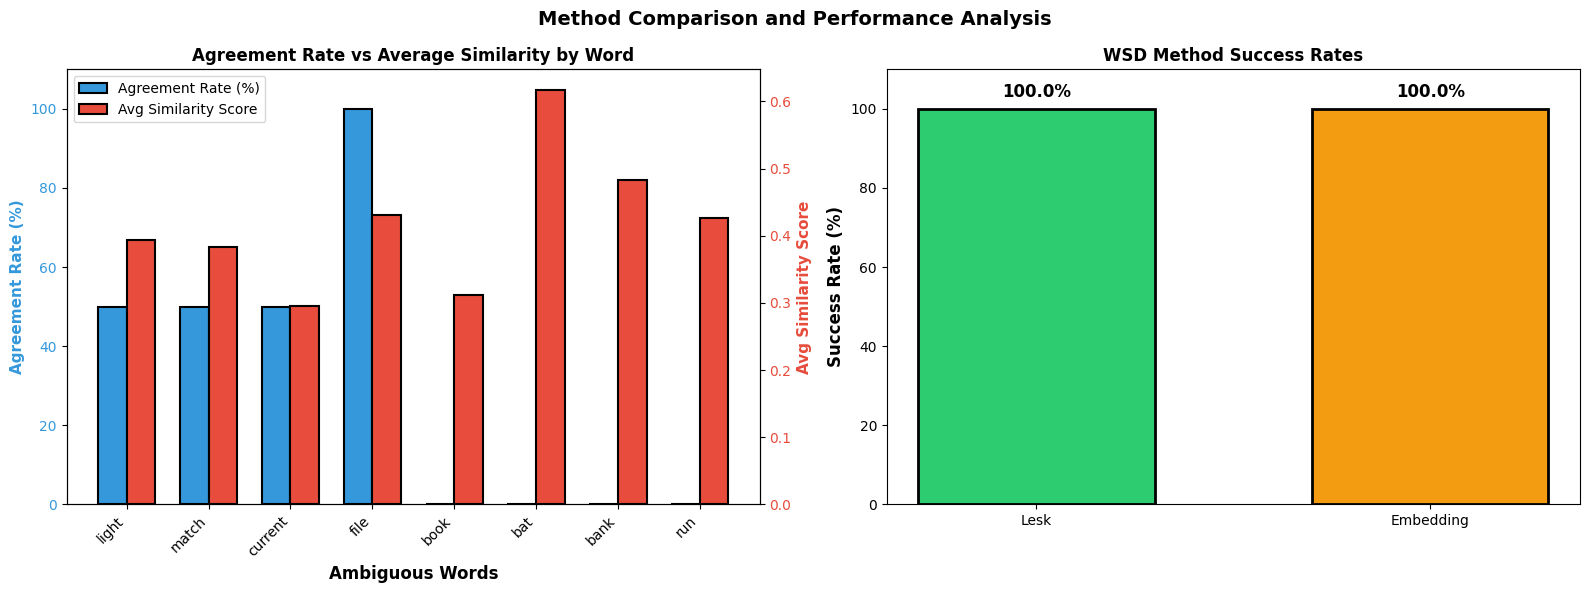

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Method Comparison and Performance Analysis', fontsize=14, fontweight='bold')

ax1 = axes[0]
word_list = analysis_df['Word'].tolist()
agreement_rates = [float(x.strip('%')) for x in analysis_df['Agreement %'].tolist()]
avg_similarities = [float(x) for x in analysis_df['Avg Similarity'].tolist()]

x = np.arange(len(word_list))
width = 0.35

bars1 = ax1.bar(x - width/2, agreement_rates, width, label='Agreement Rate (%)', 
                color='#3498db', edgecolor='black', linewidth=1.5)
ax1_twin = ax1.twinx()
bars2 = ax1_twin.bar(x + width/2, avg_similarities, width, label='Avg Similarity Score',
                     color='#e74c3c', edgecolor='black', linewidth=1.5)

ax1.set_xlabel('Ambiguous Words', fontsize=12, fontweight='bold')
ax1.set_ylabel('Agreement Rate (%)', fontsize=11, fontweight='bold', color='#3498db')
ax1_twin.set_ylabel('Avg Similarity Score', fontsize=11, fontweight='bold', color='#e74c3c')
ax1.set_title('Agreement Rate vs Average Similarity by Word', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(word_list, rotation=45, ha='right')
ax1.tick_params(axis='y', labelcolor='#3498db')
ax1_twin.tick_params(axis='y', labelcolor='#e74c3c')
ax1.set_ylim(0, 110)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_twin.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10)

ax2 = axes[1]
methods = ['Lesk', 'Embedding']
success_rates = [
    (lesk_df['found'].sum() / len(lesk_df) * 100),
    (embedding_df['found'].sum() / len(embedding_df) * 100)
]
colors_methods = ['#2ecc71', '#f39c12']
bars = ax2.bar(methods, success_rates, color=colors_methods, edgecolor='black', linewidth=2, width=0.6)
ax2.set_ylabel('Success Rate (%)', fontsize=12, fontweight='bold')
ax2.set_title('WSD Method Success Rates', fontsize=12, fontweight='bold')
ax2.set_ylim(0, 110)

for bar, rate in zip(bars, success_rates):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 2,
            f'{rate:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()